Form has no parts with arity 2.


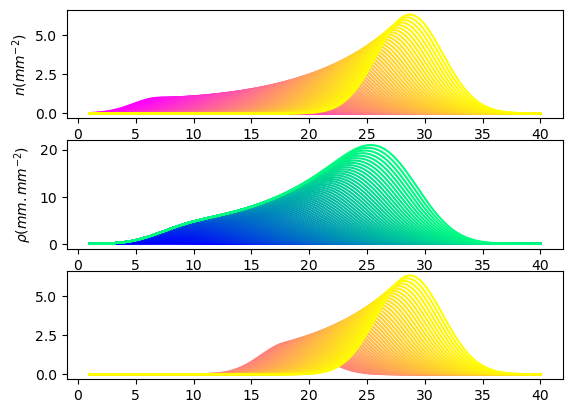

In [2]:
from dolfin import *
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

plt.close("all")
set_log_active(False)

cmap2 = mpl.colormaps["spring"]
cmap = mpl.colormaps["winter"]

# Define the problem
Length = 40 # 40.0
nx = 200 # 200
nT = 900 # 900
keep = 10
mesh = IntervalMesh(nx, 1, Length)
P1 = FiniteElement('P', interval, 1)
element = MixedElement([P1, P1])
V = FunctionSpace(mesh, element)

density_tip = np.zeros((int(nT / keep), nx))
density_in = np.zeros((int(nT / keep), nx))

# Define the parameters
T = 90 # 90 (hours)
dt = T/nT
alphval = 0.039 # 0.039
# cval = 0.6
# Define the initial condition
u0 = Expression(('1*exp(-0.1*pow(abs(x[0]-7),2))',0), degree=1)
#define radial coordinate
rexp = Expression(('1/x[0]',0),degree=1)
r = interpolate(rexp, V)
invr, _ = split(r)
# Define other elements

u_n = interpolate(u0, V)
u = Function (V)
n, rho = split(u)
n_n, rho_n= split(u_n)
v_1, v_2 = TestFunctions(V)
k = Constant((1,))

s_scal = Constant(0.2) # 0.2
beta = 0.00000000000000000000000000000001 # Constant(0.022) # Constant(0.022)
alpha = Constant(alphval)
D = Constant(0.02) # Constant(0.02)

n_mid = 0.5*(n_n + n)
v_sval = 0.235 # 0.235
v_s = Constant((v_sval,))


F = n*v_1*dx - n_n*v_1*dx 
#Diffusion coefficient
F += D*dot(grad(n), grad(v_1))*dt*dx
# To account for cylindrical coordinates
F += invr*D*dot(grad(n), Constant((1,)))*v_1*dt*dx
F += dt*dot(grad(n_mid),v_s)*v_1*dx
# To account for cylindrical coordinates
F += invr*dt*n_mid*Constant(v_sval)*v_1*dx



F -=dt*s_scal*n*v_2*dx-(rho-rho_n)*v_2*dx
F += beta*v_1*rho*(n)*dt*dx
F -= alpha*(n)*v_1*dt*dx

# Apply the boundary conditions
u_L = (Constant(0.0),Constant(0.0))
u_R = (Constant(0.0),Constant(0.0))
bc_L = DirichletBC(V, u_L, 'near(x[0], 1.0)')
bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
bcs = [bc_L, bc_R]

# bc = PeriodicBC(V, Boundary())# Solve the problem
t = 0.0
a, L = lhs(F), rhs(F)
V2 = FunctionSpace(mesh, 'P', 1)
X = np.linspace(1,Length,nx)
poss = []

fix,axs = plt.subplots(3,1)
i=0
for t in np.linspace(0,T,nT):

    solve(F==0, u,bcs)
    u_n.assign(u)
    _n, _rho= u.split()
    n_field = interpolate(_n, V2)

    if i%keep==0:# i%100==0:
        rho_field = interpolate(_rho, V2)
        if i%keep==0:
            axs[0].plot(X,[n_field(x) for x in X],color=cmap2(t/T))
            axs[1].plot(X,[rho_field(x) for x in X],color=cmap(t/T))
        if i > nT / 2:
            axs[2].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
            
        density_tip[int(i / 10), :] = [n_field(x) for x in X]
        density_in[int(i / 10), :] = [rho_field(x) for x in X]
        
    poss.append(np.argmax([n_field(x) for x in X]))
    i+=1
    
    # break
axs[0].set_xlabel('')
axs[0].set_ylabel('$n (mm^{-2})$')

axs[1].set_xlabel('position ($mm$)')
axs[1].set_ylabel(r'$\rho (mm.mm^{-2})$')

plt.show()

In [1]:
%matplotlib widget
from dolfin import *
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

plt.close("all")
set_log_active(False)

cmap2 = mpl.colormaps["spring"]
cmap = mpl.colormaps["winter"]

# Define the problem
Length = 1.0
left = 1e-3 # small positive left end to avoid 1/x singularity
nx = 100
nT = 340
keep = 10
mesh = IntervalMesh(nx, left, Length)
P1 = FiniteElement('P', interval, 1)
element = MixedElement([P1, P1])
V = FunctionSpace(mesh, element)

density_tip = np.zeros((int(nT / keep), nx))
density_in = np.zeros((int(nT / keep), nx))

# Define the parameters
T = 34 # (hours)
dt = T / nT
alphval = 0.15
cval = 0.6

# Define the initial condition
u0 = Expression(('3500*exp(-230000*pow(x[0]-0.01,2))', '0.0'), degree=1)

# define radial coordinate
rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
r = interpolate(rexp, V)
invr, _ = split(r)

# Define other elements
u_n = interpolate(u0, V)
u = Function(V)
n, rho = split(u)
n_n, rho_n = split(u_n) 
v_1, v_2 = TestFunctions(V)
k = Constant((1,))

s_scal = Constant(0.0288)
beta = Constant(0.01013)
alpha = Constant(alphval)
D = Constant(3.6e-4)

n_mid = 0.5 * (n_n + n)
v_sval = 0.012 # 0.014
v_s = Constant((v_sval,))

# F = n*v_1*dx - n_n*v_1*dx 
# #Diffusion coefficient
# F += D*dot(grad(n), grad(v_1))*dt*dx
# # To account for cylindrical coordinates
# F += invr*D*dot(grad(n), Constant((1,)))*v_1*dt*dx
# F += dt*dot(grad(n_mid),v_s)*v_1*dx
# # To account for cylindrical coordinates
# F += invr*dt*n_mid*Constant(v_sval)*v_1*dx

# F -=dt*s_scal*n*v_2*dx-(rho-rho_n)*v_2*dx
# F += beta*v_1*rho**2*(n)*dt*dx
# F -= alpha*(n)*v_1*dt*dx

# # Apply the boundary conditions
# u_L = (Constant(0.0),Constant(0.0))
# u_R = (Constant(0.0),Constant(0.0))
# bc_L = DirichletBC(V, u_L, 'near(x[0], 1.0)')
# bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
# bcs = [bc_L, bc_R]

F = n * v_1 * dx - n_n * v_1 * dx
# Diffusion term
F += D * dot(grad(n), grad(v_1)) * dt * dx
# Cylindrical correction terms using invr
F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
F += dt * dot(grad(n_mid), v_s) * v_1 * dx
F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx

F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
F += beta * v_1 * rho * n * dt * dx
F -= alpha * n * v_1 * dt * dx

# Apply the boundary conditions (left=left, right=Length)
u_L = (Constant(0.0), Constant(0.0))
u_R = (Constant(0.0), Constant(0.0))
bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
bcs = [bc_L, bc_R]

t = 0.0
a, L = lhs(F), rhs(F)
V2 = FunctionSpace(mesh, 'P', 1)
X = np.linspace(left, Length, nx)
poss = []

fig, axs = plt.subplots(3, 1)
i = 0
for t in np.linspace(0, T, nT):
    solve(F == 0, u, bcs)
    u_n.assign(u)
    _n, _rho = u.split()
    n_field = interpolate(_n, V2)

    if i % keep == 0:
        rho_field = interpolate(_rho, V2)
        axs[0].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
        axs[1].plot(X, [rho_field(x) for x in X], color=cmap(t / T))

        density_tip[int(i / keep), :] = [n_field(x) for x in X]
        density_in[int(i / keep), :] = [rho_field(x) for x in X]
        if i > nT / 2:
            axs[2].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
    poss.append(np.argmax([n_field(x) for x in X]))
    i += 1

axs[0].set_xlabel('')
axs[0].set_ylabel('$n (mm^{-2})$')
axs[1].set_xlabel('position ($mm$)')
axs[1].set_ylabel(r'$\rho (mm.mm^{-2})$')

/Users/laurenyan/opt/anaconda3/envs/fungi_surrogate_env/lib/python3.14/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Form has no parts with arity 2.


Text(0, 0.5, '$\\rho (mm.mm^{-2})$')

Text(0, 0.5, 'x ($mm$)')

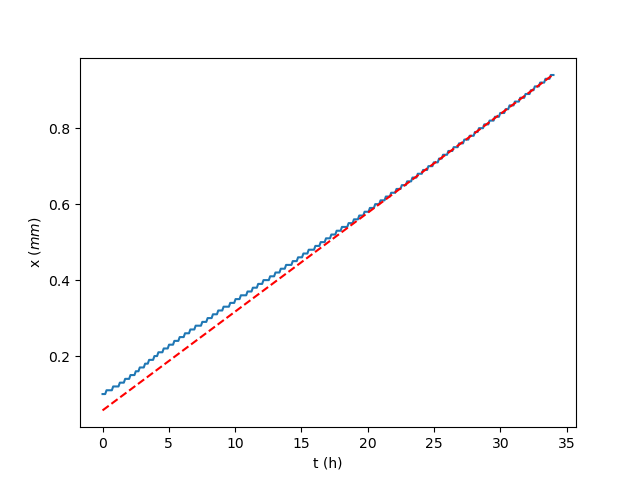

In [54]:
x = np.linspace(0,T,nT)
y = np.array(poss)*Length/nx
fit_coeffs = np.polyfit(x[3*nT//4:], y[3*nT//4:], 1)
fit_line = np.polyval(fit_coeffs, x)

# Plot data and linear fit
fig, ax = plt.subplots()
ax.plot(x, y)
ax.plot(x, fit_line, 'r--')
ax.set_xlabel('t (h)')
ax.set_ylabel('x ($mm$)')

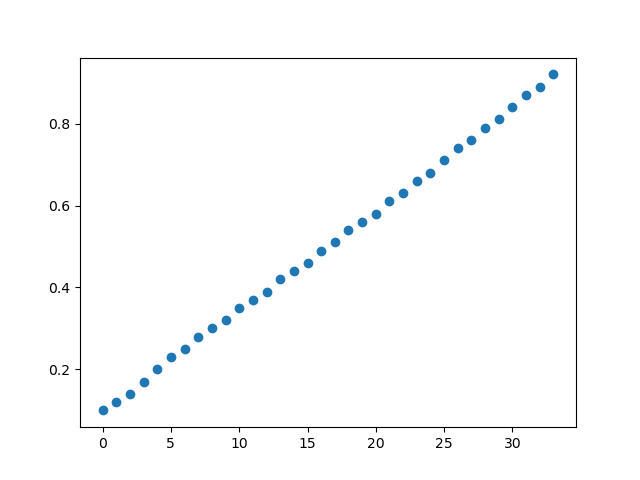

In [55]:
x = np.arange(0,T, 1)
y = np.array(poss[::keep])*Length/nx
fig, ax = plt.subplots()
ax.scatter(x, y)

In [64]:
# def compute_peak_width(x, y):
#     # Get y values and find maximum
#     max_y = max(y)
#     max_index = y.index(max_y)
#     half_max_y = max_y / 2

#     # Find the index where y first exceeds half_max_y before the peak
#     start = 0
#     for i in range(max_index, -1, -1):
#         if y[i] < half_max_y:
#             start = i
#             break

#     # Find the index where y first drops below half_max_y after the peak
#     end = len(x) - 1
#     for i in range(max_index, len(x)):
#         if y[i] < half_max_y:
#             end = i
#             break

#     # Return the difference in x values at these indices
#     return x[end] - x[start]
# compute_peak_width(X,[n_field(x) for x in X])

In [57]:
from scipy.optimize import curve_fit
from scipy.interpolate import CubicSpline

In [58]:
def sigmoid_r(r, K, L, r0, b):
    return K / (1 + np.exp(-L * (r0 - r))) + b

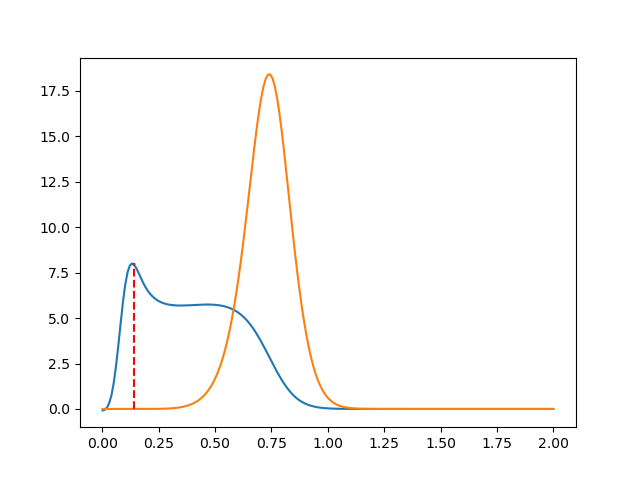

In [59]:
to_fit = 26
to_fit_in = density_in[to_fit, :]
to_fit_tip = density_tip[to_fit, :]
cs = CubicSpline(X, to_fit_in)
for i in range(len(X)):
    if cs(X, 1)[i] < 0 and cs(X, 1)[i-1] > 0:
        cutoff = i
        break
plt.figure()
plt.plot(X, to_fit_in)
plt.plot(X, to_fit_tip)
plt.vlines(X[cutoff], 0, np.max(density_in), color = 'r', linestyle = '--')

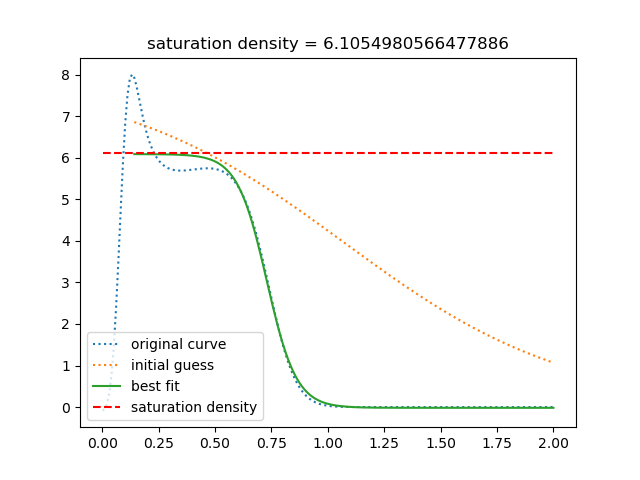

In [60]:
plt.figure()
# if cutoff < np.argmax(to_fit_in):
#     plt.plot(X[cutoff:], to_fit_in[cutoff:], ':', label = 'original curve')
#     plt.hlines(np.max(to_fit_in), np.min(X[cutoff:]), np.max(X[cutoff:]), color = 'r', linestyle = '--', label = 'saturation density')
#     plt.title('saturation density = ' + str(np.max(to_fit_in)))
#     plt.legend(loc = 'lower right')
#     density_sat = np.max(to_fit_in)
# else:
K_guess = np.max(to_fit_in[cutoff:])
L_guess = np.max(X) # np.min(X[cutoff:])
r0_guess = np.median(X[cutoff:])
b_guess = 0
p0_sig = [K_guess, L_guess, r0_guess, b_guess] # initial guess 
popt_sig, pcov_sig = curve_fit(sigmoid_r, X[cutoff:], to_fit_in[cutoff:], p0_sig)
plt.plot(X, to_fit_in, ':', label = 'original curve')
if popt_sig[0] > np.max(to_fit_in) or popt_sig[0] < 0:
    plt.plot(X[cutoff:], sigmoid_r(X[cutoff:], popt_sig[0], popt_sig[1], popt_sig[2], popt_sig[3]), label = 'best fit')
    plt.hlines(np.max(to_fit_in), np.min(X[cutoff:]), np.max(X[cutoff:]), color = 'r', linestyle = '--', label = 'saturation density')
    plt.title('saturation density = ' + str(np.max(to_fit_in)))
    plt.legend(loc = 'lower right')
    density_sat = np.max(to_fit_in)
else:
    plt.plot(X[cutoff:], sigmoid_r(X[cutoff:], K_guess, L_guess, r0_guess, b_guess), ':', label = 'initial guess')
    plt.plot(X[cutoff:], sigmoid_r(X[cutoff:], popt_sig[0], popt_sig[1], popt_sig[2], popt_sig[3]), label = 'best fit')
    plt.hlines(popt_sig[0], np.min(X), np.max(X), color = 'r', linestyle = '--', label = 'saturation density')
    plt.title('saturation density = ' + str(popt_sig[0]))
    plt.legend(loc = 'lower left')
    density_sat = popt_sig[0]

10 fit
11 fit
12 fit
13 fit
14 fit
15 fit
16 fit
17 fit
18 fit
19 fit
20 fit
21 fit
22 fit
23 fit
24 fit
25 fit
26 fit
27 fit
28 fit
29 fit
30 fit
31 fit
32 fit
33 fit


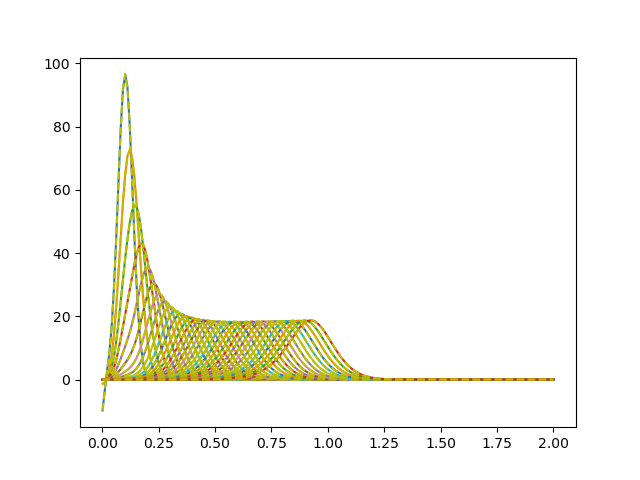

In [65]:
saturation_density = []
area = []
plt.figure()
for t in range(T):
    to_fit_in = density_in[t, :]
    to_fit_tip = density_tip[t, :]
    cs_in = CubicSpline(X, to_fit_in)
    cs_tip = CubicSpline(X, to_fit_tip)
    area.append(cs_tip.integrate(X[0], X[-1]))
    for i in range(len(X)):
        if cs_in(X, 1)[i] < 0 and cs_in(X, 1)[i-1] > 0:
            cutoff = i
            break
    # plt.figure()
    # plt.plot(X, to_fit_in)
    # plt.plot(X, to_fit_tip)
    # plt.vlines(X[cutoff], 0, np.max(density_in), color = 'r', linestyle = '--')

    # plt.figure()
    # if cutoff < np.argmax(to_fit_in):
    #     plt.plot(X[cutoff:], to_fit_in[cutoff:], ':', label = 'original curve')
    #     plt.hlines(np.max(to_fit_in), np.min(X[cutoff:]), np.max(X[cutoff:]), color = 'r', linestyle = '--', label = 'saturation density')
    #     plt.title('saturation density = ' + str(np.max(to_fit_in)))
    #     plt.legend(loc = 'lower right')
    #     density_sat = np.max(to_fit_in)
    # else:
    try:
        K_guess = np.max(to_fit_in[cutoff:])
        L_guess = np.max(X) # np.min(X[cutoff:])
        r0_guess = np.median(X[cutoff:])
        b_guess = 0
        p0_sig = [K_guess, L_guess, r0_guess, b_guess] # initial guess 
        popt_sig, pcov_sig = curve_fit(sigmoid_r, X[cutoff:], to_fit_in[cutoff:], p0_sig)
        plt.plot(X, to_fit_tip, label = 'original curve')
        plt.plot(X, cs_tip(X), 'y--')
        if popt_sig[0] > np.max(to_fit_in) or popt_sig[0] < 0:
            # plt.hlines(np.max(to_fit_in), np.min(X[cutoff:]), np.max(X[cutoff:]), color = 'r', linestyle = '--', label = 'saturation density')
            # plt.title('saturation density = ' + str(np.max(to_fit_in)))
            # plt.legend(loc = 'lower right')
            density_sat = np.max(to_fit_in)
        else:
            # plt.plot(X[cutoff:], sigmoid_r(X[cutoff:], K_guess, L_guess, r0_guess, b_guess), ':', label = 'initial guess')
            # plt.plot(X[cutoff:], sigmoid_r(X[cutoff:], popt_sig[0], popt_sig[1], popt_sig[2], popt_sig[3]), label = 'best fit')
            # plt.hlines(popt_sig[0], np.min(X), np.max(X), color = 'r', linestyle = '--', label = 'saturation density')
            # plt.title('saturation density = ' + str(popt_sig[0]))
            # plt.legend(loc = 'lower left')
            density_sat = popt_sig[0]
            print(str(t) + ' fit')
    except RuntimeError as e:
        density_sat = np.max(to_fit_in)
        print('hour ' + str(t))
        print(e)
    saturation_density.append(density_sat)

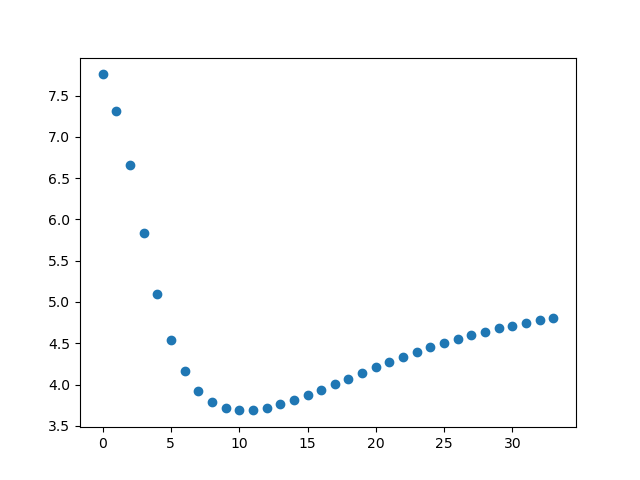

In [62]:
plt.figure()
plt.scatter(range(T), area)

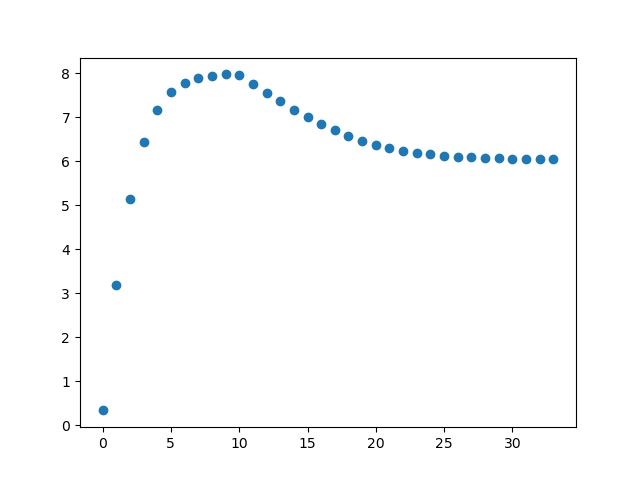

In [63]:
plt.figure()
plt.scatter(range(T), saturation_density)

In [3]:
import pandas as pd
from dolfin import *
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

alpha = 0.1933052745482837
beta = 0.0034807004068066
vd = 0.0034807004068066
sg = 0.0203594949515522
D = 3.623603918286951e-05
saturation density = 111.07263019263033
Form has no parts with arity 2.


RuntimeError: 

*** -------------------------------------------------------------------------
*** DOLFIN encountered an error. If you are not able to resolve this issue
*** using the information listed below, you can ask for help at
***
***     fenics-support@googlegroups.com
***
*** Remember to include the error message listed below and, if possible,
*** include a *minimal* running example to reproduce the error.
***
*** -------------------------------------------------------------------------
*** Error:   Unable to solve nonlinear system with NewtonSolver.
*** Reason:  Newton solver did not converge because maximum number of iterations reached.
*** Where:   This error was encountered inside NewtonSolver.cpp.
*** Process: 0
*** 
*** DOLFIN version: 2019.1.0
*** Git changeset:  
*** -------------------------------------------------------------------------


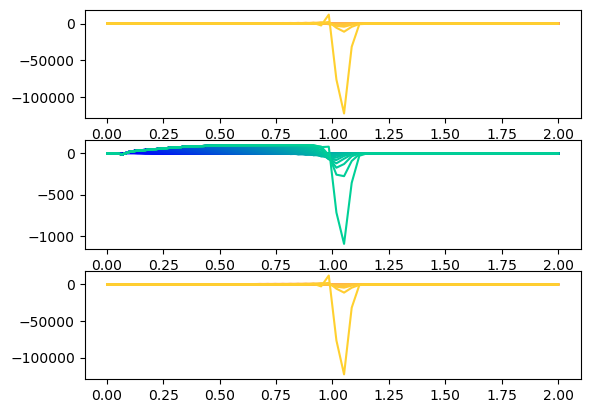

In [13]:
sim_name = 'output_fungi_118'
z_const = pd.read_csv(sim_name + '_data_const.csv')      
alpha_test = z_const['alpha'][0]
beta_test = z_const['beta'][0]
vd_test = z_const['vd'][0]
sg_test = z_const['sg'][0]
D_test = z_const['D'][0]
upar = [z_const['A'][0], z_const['s'][0], z_const['r0'][0]]
upar[2] = 0.1
sat = 2 * alpha_test / beta_test

print('alpha = ' + str(alpha_test))
print('beta = ' + str(beta_test))
print('vd = ' + str(beta_test))
print('sg = ' + str(sg_test))
print('D = ' + str(D_test))
print('saturation density = ' + str(sat))

plt.close("all")
set_log_active(False)

cmap2 = mpl.colormaps["spring"]
cmap = mpl.colormaps["winter"]

# Define the problem
Length = 2
left = 1e-3 # small positive left end to avoid 1/x singularity
nx = Length * 50
T = 80 # (hours)
nT = T * 10
keep = 10
mesh = IntervalMesh(nx, left, Length)
P1 = FiniteElement('P', interval, 1)
element = MixedElement([P1, P1])
V = FunctionSpace(mesh, element)

density_tip = np.zeros((int(nT / keep), nx))
density_in = np.zeros((int(nT / keep), nx))

# Define the parameters

dt = T / nT
alphval = alpha_test
cval = 0.6

# Define the initial condition
u0_str = str(upar[0]) + '*exp(-0.5*' + str(upar[1]) + '*pow(abs(x[0]-' + str(upar[2]) + '),2))'
u0 = Expression((u0_str, '0.0'), degree=1)

# define radial coordinate
rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
r = interpolate(rexp, V)
invr, _ = split(r)

# Define other elements
u_n = interpolate(u0, V)
u = Function(V)
n, rho = split(u)
n_n, rho_n = split(u_n) 
v_1, v_2 = TestFunctions(V)
k = Constant((1,))

s_scal = Constant(sg_test)
beta = Constant(beta_test)
alpha = Constant(alphval)
D = Constant(D_test)

n_mid = 0.5 * (n_n + n)
v_sval = vd_test # 0.014
v_s = Constant((v_sval,))

F = n * v_1 * dx - n_n * v_1 * dx
# Diffusion term
F += D * dot(grad(n), grad(v_1)) * dt * dx
# Cylindrical correction terms using invr
F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
F += dt * dot(grad(n_mid), v_s) * v_1 * dx
F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx

F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
F += beta * v_1 * rho * n * dt * dx
F -= alpha * n * v_1 * dt * dx

# Apply the boundary conditions (left=left, right=Length)
u_L = (Constant(0.0), Constant(0.0))
u_R = (Constant(0.0), Constant(0.0))
bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
bcs = [bc_L, bc_R]

t = 0.0
a, L = lhs(F), rhs(F)
V2 = FunctionSpace(mesh, 'P', 1)
X = np.linspace(left, Length, nx)
poss = []

fig, axs = plt.subplots(3, 1)
i = 0
for t in np.linspace(0, T, nT):
    solve(F == 0, u, bcs)
    u_n.assign(u)
    _n, _rho = u.split()
    n_field = interpolate(_n, V2)
    
    if i % keep == 0:
        rho_field = interpolate(_rho, V2)
        axs[0].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
        axs[1].plot(X, [rho_field(x) for x in X], color=cmap(t / T))

        density_tip[int(i / keep), :] = [n_field(x) for x in X]
        density_in[int(i / keep), :] = [rho_field(x) for x in X]
        if i > nT / 2:
            axs[2].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
    poss.append(np.argmax([n_field(x) for x in X]))
    i += 1

axs[0].set_xlabel('')
axs[0].set_ylabel('$n (mm^{-2})$')
axs[1].set_xlabel('position ($mm$)')
axs[1].set_ylabel(r'$\rho (mm.mm^{-2})$')

Form has no parts with arity 2.


Text(0, 0.5, '$\\rho (mm.mm^{-2})$')

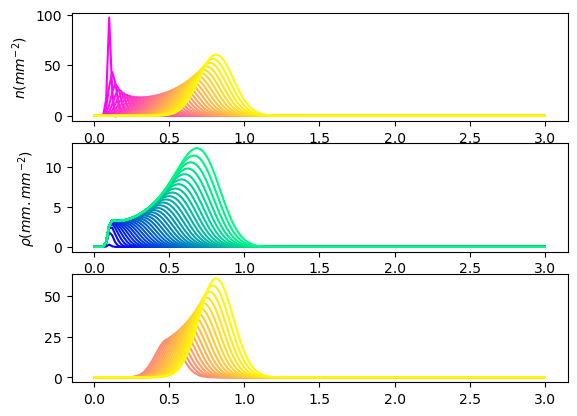

In [8]:
alpha_test = 0.12
beta_test = 0.0009
vd_test = 0.02
sg_test = 0.03
D_test = 0.0002
upar = [118, 11800, 0.1]

plt.close("all")
set_log_active(False)

cmap2 = mpl.colormaps["spring"]
cmap = mpl.colormaps["winter"]

# Define the problem
Length = 3
left = 1e-3 # small positive left end to avoid 1/x singularity
nx = Length * 50
T = 34 # (hours)
nT = T * 10
keep = 10
mesh = IntervalMesh(nx, left, Length)
P1 = FiniteElement('P', interval, 1)
element = MixedElement([P1, P1])
V = FunctionSpace(mesh, element)

density_tip = np.zeros((int(nT / keep), nx))
density_in = np.zeros((int(nT / keep), nx))

# Define the parameters

dt = T / nT
alphval = alpha_test
cval = 0.6

# Define the initial condition
u0_str = str(upar[0]) + '*exp(-0.5*' + str(upar[1]) + '*pow(abs(x[0]-' + str(upar[2]) + '),2))'
u0 = Expression((u0_str, '0.0'), degree=1)

# define radial coordinate
rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
r = interpolate(rexp, V)
invr, _ = split(r)

# Define other elements
u_n = interpolate(u0, V)
u = Function(V)
n, rho = split(u)
n_n, rho_n = split(u_n) 
v_1, v_2 = TestFunctions(V)
k = Constant((1,))

s_scal = Constant(sg_test)
beta = Constant(beta_test)
alpha = Constant(alphval)
D = Constant(D_test)

n_mid = 0.5 * (n_n + n)
v_sval = vd_test # 0.014
v_s = Constant((v_sval,))

F = n * v_1 * dx - n_n * v_1 * dx
# Diffusion term
F += D * dot(grad(n), grad(v_1)) * dt * dx
# Cylindrical correction terms using invr
F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
F += dt * dot(grad(n_mid), v_s) * v_1 * dx
F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx

F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
F += beta * v_1 * rho * n * dt * dx
F -= alpha * n * v_1 * dt * dx

# Apply the boundary conditions (left=left, right=Length)
u_L = (Constant(0.0), Constant(0.0))
u_R = (Constant(0.0), Constant(0.0))
bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
bcs = [bc_L, bc_R]

t = 0.0
a, L = lhs(F), rhs(F)
V2 = FunctionSpace(mesh, 'P', 1)
X = np.linspace(left, Length, nx)
poss = []

fig, axs = plt.subplots(3, 1)
i = 0
for t in np.linspace(0, T, nT):
    solve(F == 0, u, bcs)
    u_n.assign(u)
    _n, _rho = u.split()
    n_field = interpolate(_n, V2)
    
    if i % keep == 0:
        rho_field = interpolate(_rho, V2)
        axs[0].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
        axs[1].plot(X, [rho_field(x) for x in X], color=cmap(t / T))

        density_tip[int(i / keep), :] = [n_field(x) for x in X]
        density_in[int(i / keep), :] = [rho_field(x) for x in X]
        if i > nT / 2:
            axs[2].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
    poss.append(np.argmax([n_field(x) for x in X]))
    i += 1

axs[0].set_xlabel('')
axs[0].set_ylabel('$n (mm^{-2})$')
axs[1].set_xlabel('position ($mm$)')
axs[1].set_ylabel(r'$\rho (mm.mm^{-2})$')

In [7]:
2 * alpha_test / beta_test

266.6666666666667